<a href="https://colab.research.google.com/github/oq7oq/Alphasia-project/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import os

# طباعة المجلدات الموجودة في الصفحة الرئيسية لـ Google Drive
drive_path = "/content/drive/MyDrive"

print("📂 المجلدات الموجودة في Google Drive لديك:")
for item in os.listdir(drive_path):
    if os.path.isdir(os.path.join(drive_path, item)) and not item.startswith('.'):
        print(f" - {item}")



📂 المجلدات الموجودة في Google Drive لديك:
 - Colab Notebooks
 - iLovePDF
 - Google Earth Studio
 - aphasia-ecosystem


In [10]:
import os
from pathlib import Path

# 1. تحديد مسار المشروع في Drive
data_dir = Path("/content/drive/MyDrive/aphasia-ecosystem/data/raw")

# إذا لم يجد مجلد data/raw الفرعي، سيفحص مجلد المشروع الرئيسي مباشرة
if not data_dir.exists():
    print(f"⚠️ لم يتم العثور على data/raw، جاري البحث داخل المجلد الرئيسي مباشرة...")
    data_dir = Path("/content/drive/MyDrive/aphasia-ecosystem")

if not data_dir.exists():
    print(f"❌ المجلد غير موجود. يرجى التأكد من المسمى داخل Google Drive.")
else:
    print(f"✅ تم العثور على المجلد في المسار: {data_dir}\n")

    # حصر الملفات
    video_files = list(data_dir.glob("**/*.mp4"))
    transcript_files = list(data_dir.glob("**/*.cha"))

    print("=== 📊 ملخص البيانات الحالية ===")
    print(f"عدد ملفات الفيديو (.mp4): {len(video_files)}")
    print(f"عدد ملفات التفريغ النصي (.cha): {len(transcript_files)}")
    print("-" * 35)

    print("شريحة من أسماء ملفات الفيديو:")
    for f in video_files[:5]:
        print(f" - {f.name}")

    print("\nشريحة من أسماء ملفات التفريغ النصي:")
    for f in transcript_files[:5]:
        print(f" - {f.name}")

⚠️ لم يتم العثور على data/raw، جاري البحث داخل المجلد الرئيسي مباشرة...
✅ تم العثور على المجلد في المسار: /content/drive/MyDrive/aphasia-ecosystem

=== 📊 ملخص البيانات الحالية ===
عدد ملفات الفيديو (.mp4): 11
عدد ملفات التفريغ النصي (.cha): 11
-----------------------------------
شريحة من أسماء ملفات الفيديو:
 - adler07a.mp4
 - adler05a.mp4
 - adler04a.mp4
 - adler03a.mp4
 - adler01a.mp4

شريحة من أسماء ملفات التفريغ النصي:
 - adler05a.cha
 - adler04a.cha
 - adler08a.cha
 - adler02a.cha
 - adler09a.cha


In [11]:
# 1. اختيار أول ملف .cha من القائمة التي وجدناها
sample_cha = transcript_files[0]

print(f"📄 معاينة محتوى الملف: {sample_cha.name}\n")
print("=" * 40)

# 2. قراءة أول 20 سطر من الملف
with open(sample_cha, 'r', encoding='utf-8', errors='ignore') as f:
    lines = [f.readline() for _ in range(20)]
    for line in lines:
        print(line.strip())

print("=" * 40)

📄 معاينة محتوى الملف: adler05a.cha

@UTF8
@PID:	11312/t-00017831-1
@Begin
@Languages:	eng
@Participants:	INV Investigator, PAR Participant
@ID:	eng|Adler|INV|||||Investigator|||
@ID:	eng|Adler|PAR|68;02.|female|Conduction||Participant||65.5|
@Comment:	[ba3 morphotag | engine=stanza-1.11.1 ; lang=eng | 2026-05-07T07:13:40-04:00]
@Media:	adler05a, video
*INV:	www .
%exp:	pre-task conversation
@G:	Speech
*INV:	I'm gonna be asking you to do some talking . 8446_10448
%mor:	pron|I-Prs-Nom-S1~aux|be-Fin-Ind-Pres-S1 verb|go-Part-Pres-S~part|to aux|be-Inf-S verb|ask-Part-Pres-S pron|you-Prs-Acc-S2 part|to verb|do-Inf-S det|some-Def-Ind noun|talking-Acc-Ger .
%gra:	1|3|NSUBJ 2|3|AUX 3|0|ROOT 4|6|MARK 5|6|AUX 6|3|XCOMP 7|6|IOBJ 8|9|MARK 9|6|XCOMP 10|11|DET 11|9|OBJ 12|3|PUNCT
*INV:	how do you think your speech is these days ? 11021_12941
%mor:	adv|how aux|do-Fin-Ind-Pres-S2 pron|you-Prs-Nom-S2 verb|think-Inf-S pron|your-Prs-Gen-S2 noun|speech aux|be-Fin-Ind-Pres-S3 det|this-Def-Dem-Plur noun|

In [12]:
import re

print(f"🗣️ كلام المريض المستخرج من ملف: {sample_cha.name}")
print("=" * 40)

with open(sample_cha, 'r', encoding='utf-8', errors='ignore') as f:
    for line in f:
        # نبحث فقط عن الأسطر التي تبدأ بكلام المريض
        if line.startswith('*PAR:'):
            # 1. إزالة كلمة *PAR: من البداية
            clean_text = line.replace('*PAR:\t', '').replace('*PAR:', '')

            # 2. إزالة أرقام التوقيتات التي بين الأقواس  
            clean_text = re.sub(r'.*?', '', clean_text)

            # 3. طباعة النص بعد التنظيف
            print(clean_text.strip())

print("=" * 40)

🗣️ كلام المريض المستخرج من ملف: adler05a.cha
&-uh fair .
yes [=! laughs] .
<I have> [//] sometimes I [/] I [/] &+f I [//] &=sighs I've &+t &+f trouble the voice .
and I'm awoke a that way I'm tɪðə˞@u [: x@n] [* n:uk] of .
yes .
I woke up through the night .
and I didn't know what was wrong .
I was: &=head:shake .
and I woke up in the morning and I couldn't &-uh &-uh &=ges:shirt kʌt@u [: x@n] [* n:uk] my clothes .
and I went downstairs &=clears:throat .
and &=head:shake I couldn't go anywhere .
<so I called my &-uh my> [//] &-uh <I was> [//] I called my boss .
<he was in another> [//] &-uh &-uh &+s &-uh &+ser he was in surgery .
and he called to the house .
and he called me .
and he came to me .
and I &=nods &=points:arm +...
but he [/] he [//] we are together for so long that he knew &+ex somethin(g) was goin(g) on .
&=clears:throat because <he just> [/] &=clears:throat he just knew <something was> [/] something was going on .
I [/] &+f I stayed with Hackensack Hospital .
and then I wa

In [13]:
def extract_aphasia_features(patient_text):
    """
    دالة لاستخراج الميزات اللغوية من نص مريض الحبسة
    """
    # 1. تنظيف النص الأساسي من العلامات الخاصة لحساب الكلمات الحقيقية
    # نزيل كل علامات CHAT مثل: &-uh, [/], [//], [* s:uk], &=laughs
    clean_words_only = re.sub(r'&\-\w+', '', patient_text) # إزالة &-uh و &-um
    clean_words_only = re.sub(r'\[.*?\]', '', clean_words_only) # إزالة ما بين الأقواس المربعة
    clean_words_only = re.sub(r'&=\w+:\w+|&=\w+', '', clean_words_only) # إزالة &=laughs و &=head:shake
    clean_words_only = re.sub(r'[^\w\s]', '', clean_words_only) # إزالة علامات الترقيم

    # حساب عدد الكلمات الفعلية
    words = clean_words_only.split()
    word_count = len(words)

    # 2. حساب علامات التردد والوقفات (Hesitations)
    hesitations = len(re.findall(r'&\-(uh|um|hm)', patient_text))

    # 3. حساب عدد التكرارات (Repetitions) وتصحيح الذات (Self-corrections)
    repetitions = len(re.findall(r'\[/\]', patient_text))
    self_corrections = len(re.findall(r'\[//\]', patient_text))

    # 4. حساب النسب المئوية
    hesitation_ratio = (hesitations / word_count) if word_count > 0 else 0

    # تجميع النتائج في قاموس (Dictionary)
    features = {
        "Total Words": word_count,
        "Hesitations (uh/um)": hesitations,
        "Repetitions": repetitions,
        "Self Corrections": self_corrections,
        "Hesitation Ratio": round(hesitation_ratio, 3)
    }

    return features

# ==========================================
# تجربة الدالة على النص الذي استخرجناه مسبقاً
# (سنجمع أسطر المريض في متغير واحد أولاً)
# ==========================================

full_patient_text = ""
with open(sample_cha, 'r', encoding='utf-8', errors='ignore') as f:
    for line in f:
        if line.startswith('*PAR:'):
            full_patient_text += line.replace('*PAR:\t', '').replace('*PAR:', '') + " "

# استخراج الميزات
patient_features = extract_aphasia_features(full_patient_text)

print(f"📊 تحليل الميزات للمريض في ملف: {sample_cha.name}")
print("-" * 40)
for feature_name, value in patient_features.items():
    print(f"🔹 {feature_name}: {value}")
print("-" * 40)

📊 تحليل الميزات للمريض في ملف: adler05a.cha
----------------------------------------
🔹 Total Words: 1753
🔹 Hesitations (uh/um): 133
🔹 Repetitions: 62
🔹 Self Corrections: 63
🔹 Hesitation Ratio: 0.076
----------------------------------------


In [14]:
import pandas as pd

# 1. إنشاء قائمة لتخزين بيانات جميع المرضى
all_patients_data = []

print("🔄 جاري تحليل جميع ملفات التفريغ النصي... (قد يستغرق ثواني حسب عدد الملفات)")

# 2. المرور على كل ملفات .cha
for cha_file in transcript_files:
    patient_id = cha_file.stem # استخراج اسم الملف ليكون كود المريض

    # تجميع كلام المريض من الملف الحالي
    full_patient_text = ""
    with open(cha_file, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            if line.startswith('*PAR:'):
                full_patient_text += line.replace('*PAR:\t', '').replace('*PAR:', '') + " "

    # 3. إذا كان الملف يحتوي على كلام، استخرج الميزات وأضفها للقائمة
    if full_patient_text.strip():
        features = extract_aphasia_features(full_patient_text)
        features['Patient_ID'] = patient_id
        all_patients_data.append(features)

# 4. تحويل القائمة إلى جدول بيانات (Pandas DataFrame)
df_features = pd.DataFrame(all_patients_data)

# ترتيب الأعمدة ليكون المعرف (Patient_ID) في البداية
cols = ['Patient_ID', 'Total Words', 'Hesitations (uh/um)', 'Repetitions', 'Self Corrections', 'Hesitation Ratio']
df_features = df_features[cols]

print(f"\n✅ اكتمل التحليل بنجاح! تم استخراج ميزات {len(df_features)} مريض.")
print("=" * 50)
print("📊 عينة من الجدول النهائي:")
display(df_features.head())

# 5. حفظ الجدول النهائي كملف CSV في Google Drive
# سيتم حفظه في مجلد البيانات الرئيسي (مثلاً aphasia-ecosystem/data)
if data_dir.name == 'raw':
    output_csv = data_dir.parent / "patient_features.csv"
else:
    output_csv = data_dir / "patient_features.csv"

df_features.to_csv(output_csv, index=False)
print("=" * 50)
print(f"💾 تم حفظ ملف البيانات الجاهزة للذكاء الاصطناعي في:\n{output_csv}")

🔄 جاري تحليل جميع ملفات التفريغ النصي... (قد يستغرق ثواني حسب عدد الملفات)

✅ اكتمل التحليل بنجاح! تم استخراج ميزات 11 مريض.
📊 عينة من الجدول النهائي:


,Patient_ID,Total Words,Hesitations (uh/um),Repetitions,Self Corrections,Hesitation Ratio
0,adler05a,1753,133,62,63,0.076
1,adler04a,803,106,17,18,0.132
2,adler08a,1076,86,81,36,0.080
3,adler02a,4032,674,503,246,0.167
4,adler09a,2224,291,131,104,0.131


💾 تم حفظ ملف البيانات الجاهزة للذكاء الاصطناعي في:
/content/drive/MyDrive/aphasia-ecosystem/patient_features.csv


/tmp/ipykernel_358/4152007365.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_features, x='Patient_ID', y='Hesitation Ratio', palette='viridis')


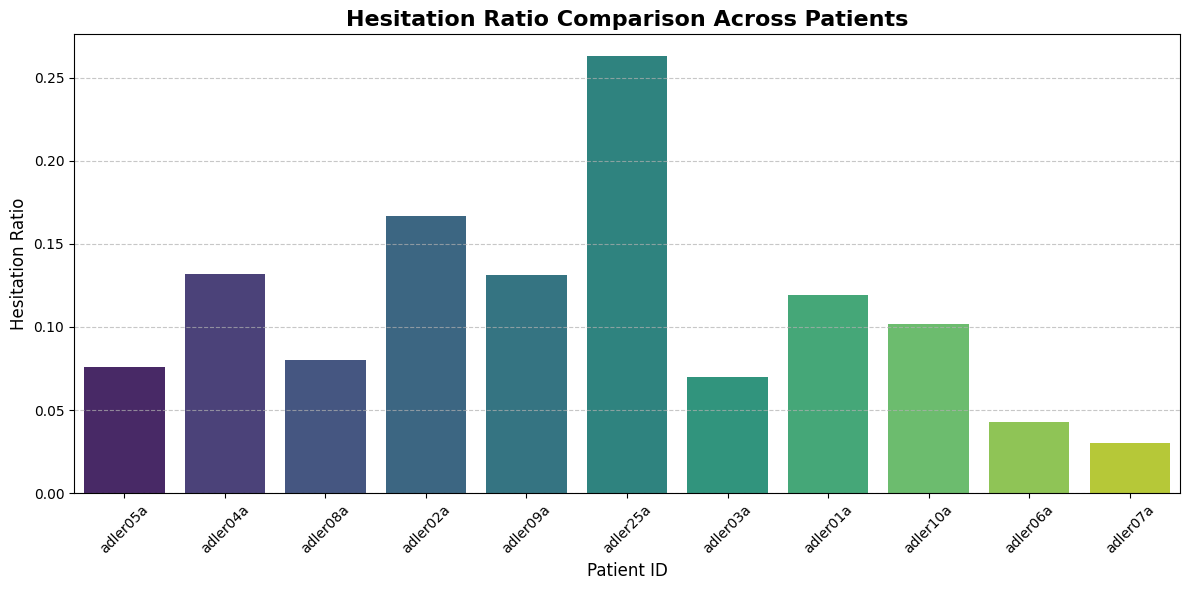

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(12, 6))

# Create the bar plot
sns.barplot(data=df_features, x='Patient_ID', y='Hesitation Ratio', palette='viridis')

# Add English titles and labels
plt.title('Hesitation Ratio Comparison Across Patients', fontsize=16, fontweight='bold')
plt.xlabel('Patient ID', fontsize=12)
plt.ylabel('Hesitation Ratio', fontsize=12)

# Format the x-axis and grid
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the plot
plt.tight_layout()
plt.show()

# Phase 1 Summary: Data Exploration & Feature Extraction
In this notebook, we successfully completed the initial data processing phase for the AphasiaBank dataset:
1. **Environment Setup:** Connected Google Colab to Google Drive and located the `data/raw` directory containing `.cha` and `.mp4` files.
2. **Data Parsing:** Read CHAT format transcripts (`.cha`), isolated patient speech (`*PAR:`), and removed timestamps/annotations.
3. **Feature Extraction:** Developed a function to calculate word count, hesitations (`&-uh`, `&-um`), repetitions (`[/]`), self-corrections (`[//]`), and hesitation ratios.
4. **Data Export:** Processed 11 patients and saved the structured data into `patient_features.csv`.
5. **Visualization:** Generated a bar chart comparing the Hesitation Ratio across all participants.

**Next Step:** Proceed to `02_audio_video_processing.ipynb` to extract and analyze audio from `.mp4` files.